In [1]:
# use sc_graph env
x=1

In [2]:
import scanpy as sc
import numpy as np
from pprint import pprint

## Viz embedding

In [3]:
# adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_both.h5ad')
# adata

In [4]:
# sc.pp.neighbors(adata)
# sc.tl.umap(adata)

In [5]:
# sc.pl.umap(adata, color=['cell_attn'], ncols=1, vmax='p99', frameon=False)

In [6]:
# adata.write('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_analysis.h5ad')

## Viz spatial

In [7]:
import os
import abc
import warnings
import pickle
from typing import Dict, List, Optional

import numpy as np
import pandas as pd
# import squidpy as sq
from anndata import AnnData, read_h5ad
from pandas import read_csv, read_excel, DataFrame
from scipy import sparse

In [8]:

# Code is taken from https://github.com/theislab/tissue/blob/e3cf4ec521af6ec7314fdc7d49c4ddb6db1a335b/tissue/data/datasets.py
# Last accessed 03.09.2025
# Authors: Mayar Ali
# Fischer, David Sebastian, Mayar Ali, Sabrina Richter, Ali Ertürk, and Fabian J. Theis. 2022. “Graph Neural Networks Learn Emergent Tissue Properties from Spatial Molecular Profiles.” bioRxiv. https://doi.org/10.1101/2022.12.08.519537.


class GraphTools:
    """GraphTools class."""

    celldata: AnnData
    img_celldata: Dict[str, AnnData]

    @staticmethod
    def _transform_a(a):
        """Compute degree transformation of adjacency matrix.
        Computes D^(-1) * (A+I), with A an adjacency matrix, I the identity matrix and D the degree matrix.
        Parameters
        ----------
        a
            sparse adjacency matrix.
        Returns
        -------
        degree transformed sparse adjacency matrix
        """
        warnings.filterwarnings(
            "ignore", message="divide by zero encountered in true_divide"
        )
        degrees = 1 / a.sum(axis=0)
        degrees[a.sum(axis=0) == 0] = 0
        degrees = np.squeeze(np.asarray(degrees))
        deg_matrix = sparse.diags(degrees)
        a_out = deg_matrix * a
        return a_out

    def _transform_all_a(self, a_dict: dict):
        """Compute degree transformation for dictionary of adjacency matrices.
        Computes D^(-1) * (A+I), with A an adjacency matrix, I the identity matrix and D the degree matrix for all
        matrices in a dictionary.
        Parameters
        ----------
        a_dict : dict
            a_dict
        Returns
        -------
        dictionary of degree transformed sparse adjacency matrices
        """
        a_transformed = {i: self._transform_a(a) for i, a in a_dict.items()}
        return a_transformed

    @staticmethod
    def _compute_distance_matrix(pos_matrix):
        """Compute distance matrix.
        Parameters
        ----------
        pos_matrix
            Position matrix.
        Returns
        -------
        distance matrix
        """
        diff = pos_matrix[:, :, None] - pos_matrix[:, :, None].T
        return (diff * diff).sum(1)

    def _get_degrees(self, max_distances: list):
        """Get dgrees.
        Parameters
        ----------
        max_distances : list
            List of maximal distances.
        Returns
        -------
        degrees
        """
        degs = {}
        degrees = {}
        for i, adata in self.img_celldata.items():
            pm = np.array(adata.obsm["spatial"])
            dist_matrix = self._compute_distance_matrix(pm)
            degs[i] = {
                dist: np.sum(dist_matrix < dist * dist, axis=0)
                for dist in max_distances
            }
        for dist in max_distances:
            degrees[dist] = [deg[dist] for deg in degs.values()]
        return degrees

    def process_node_features(
        self,
        node_feature_transformation: str,
    ):
        # Process node-wise features:
        if node_feature_transformation == "standardize_per_image":
            self._standardize_features_per_image()
        elif node_feature_transformation == "standardize_globally":
            self._standardize_overall()
        elif node_feature_transformation == "scale_observations":
            self._scale_observations()
        elif node_feature_transformation is None or node_feature_transformation == "none":
            pass
        else:
            raise ValueError("Feature transformation %s not recognized!" % node_feature_transformation)

    def _standardize_features_per_image(self):
        for adata in self.img_celldata.values():
            adata.X = adata.X - adata.X.mean(axis=0) / (adata.X.std(axis=0) + 1e-8)

    def _standardize_overall(self):
        data = np.concatenate([adata.X for adata in self.img_celldata.values()], axis=0)
        mean = data.mean(axis=0)
        std = data.std(axis=0)
        for adata in self.img_celldata.values():
            adata.X = adata.X - mean / std

    def _scale_observations(self, n: int = 100):
        """
        TPM-like scaling of observation vectors.
        Only makes sense with positive input.
        :param n: Total feature count to linearly scale observations into.
        :return:
        """
        for adata in self.img_celldata.values():
            adata.X = n * adata.X / adata.X.mean(axis=1)

In [9]:

class Dataset(GraphTools):
    """Dataset class. Inherits all functions from GraphTools."""

    def __init__(
        self,
        data_path: str,
        buffered_data_path: str = None,
        write_buffer: bool = False,
        radius: Optional[int] = None,
        coord_type: str = "generic",
        n_rings: int = 1,
        label_selection: Optional[List[str]] = None,
        n_top_genes: Optional[int] = None,
        cell_type_coarseness: str = "fine",
    ):
        """Initialize Dataset.
        Parameters
        ----------
        data_path : str
            Data path.
        radius : int
            Radius.
        label_selection : list, optional
            label selection.
        """
        self.data_path = data_path
        self.buffered_data_path = buffered_data_path
        self.cell_type_coarseness = cell_type_coarseness

        fn = f"{buffered_data_path}/buffered_data_{str(radius)}_{cell_type_coarseness}.pickle"
        if os.path.isfile(fn) and not write_buffer:
            print("Loading data from buffer")
            with open(fn, "rb") as f:
                stored_data = pickle.load(f)
            self.celldata = stored_data["celldata"]
            self.img_celldata = stored_data["img_celldata"]
            self.radius = radius
            self.img_to_patient_dict = stored_data["celldata"].uns["img_to_patient_dict"]

        else:            
            print("Loading data from raw files")
            self.register_celldata(n_top_genes=n_top_genes)
            self.register_img_celldata()
            self.register_graph_features(label_selection=label_selection)
            # self.compute_adjacency_matrices(radius=radius, coord_type=coord_type, n_rings=n_rings)
            self.radius = radius
            
            if write_buffer: 
                print("Buffering preprocessed input data")
                data_to_store = {
                    "celldata":self.celldata,
                    "img_celldata": self.img_celldata,
                    "img_to_patient_dict": self.img_to_patient_dict,
                }
                with open(fn, "wb") as f:
                    pickle.dump(obj=data_to_store, file=f)

        print(
            "Loaded %i images with complete data from %i patients "
            "over %i cells with %i cell features and %i distinct celltypes."
            % (
                len(self.img_celldata),
                len(self.patients),
                self.celldata.shape[0],
                self.celldata.shape[1],
                len(self.celldata.uns["node_type_names"]),
            )
        )

    @property
    def patients(self):
        """Return number of patients in celldata.
        Returns
        -------
        patients
        """
        return np.unique(
            np.asarray(list(self.celldata.uns["img_to_patient_dict"].values()))
        )

    def register_celldata(self, n_top_genes: Optional[int] = None):
        """Load AnnData object of complete dataset."""
        print("registering celldata")
        self._register_celldata(n_top_genes=n_top_genes)
        assert self.celldata is not None, "celldata was not loaded"

    def register_img_celldata(self):
        """Load dictionary of of image-wise celldata objects with {imgage key : anndata object of image}."""
        print("collecting image-wise celldata")
        self._register_img_celldata()
        assert self.img_celldata is not None, "image-wise celldata was not loaded"

    def register_graph_features(self, label_selection):
        """Load graph level covariates.
        Parameters
        ----------
        label_selection
            Label selection.
        """
        print("adding graph-level covariates")
        self._register_graph_features(label_selection=label_selection)

    @abc.abstractmethod
    def _register_celldata(self, n_top_genes: Optional[int] = None):
        """Load AnnData object of complete dataset."""
        pass

    @abc.abstractmethod
    def _register_img_celldata(self):
        """Load dictionary of of image-wise celldata objects with {imgage key : anndata object of image}."""
        pass

    @abc.abstractmethod
    def _register_graph_features(self, label_selection):
        """Load graph level covariates.
        Parameters
        ----------
        label_selection
            Label selection.
        """
        pass

    def size_factors(self):
        """Get size factors (Only makes sense with positive input).
        Returns
        -------
        sf_dict
        """
        # Check if irregular sums are encountered:
        for i, adata in self.img_celldata.items():
            if np.any(np.sum(adata.X, axis=1) <= 0):
                print("WARNING: found irregular node sizes in image %s" % str(i))
        # Get global mean of feature intensity across all features:
        global_mean_per_node = self.celldata.X.sum(axis=1).mean(axis=0)
        return {
            i: global_mean_per_node / np.sum(adata.X, axis=1)
            for i, adata in self.img_celldata.items()
        }

    @property
    def var_names(self):
        return self.celldata.var_names

In [10]:
class DatasetBaselZurichZenodo(Dataset):
    """DatasetBaselZurichZenodo class. Inherits all functions from Dataset."""

    cell_type_merge_dict = {
        "fine": {
            "1": "B cells",
            "2": "T and B cells",
            "3": "T cells",
            "4": "macrophages",
            "5": "T cells",
            "6": "macrophages",
            "7": "endothelial",
            "8": "stromal cells", # "vimentin hi stromal cell",
            "9": "stromal cells", # "small circular stromal cell",
            "10": "stromal cells", # "small elongated stromal cell",
            "11": "stromal cells", # "fibronectin hi stromal cell",
            "12": "stromal cells", # "large elongated stromal cell",
            "13": "stromal cells", # "SMA hi vimentin hi stromal cell",
            "14": "tumor cells", #"hypoxic tumor cell",
            "15": "tumor cells", #"apoptotic tumor cell",
            "16": "tumor cells", #"proliferative tumor cell",
            "17": "tumor cells", #"p53+ EGFR+ tumor cell",
            "18": "tumor cells", #"basal CK tumor cell",
            "19": "tumor cells", #"CK7+ CK hi cadherin hi tumor cell",
            "20": "tumor cells", #"CK7+ CK+ tumor cell",
            "21": "tumor cells", #"epithelial low tumor cell",
            "22": "tumor cells", #"CK low HR low tumor cell",
            "23": "tumor cells", #"CK+ HR hi tumor cell",
            "24": "tumor cells", #"CK+ HR+ tumor cell",
            "25": "tumor cells", #"CK+ HR low tumor cell",
            "26": "tumor cells", #"CK low HR hi p53+ tumor cell",
            "27": "tumor cells", #"myoepithelial tumor cell"
        },
        "binary": {
            "1": "immune cells",
            "2": "immune cells",
            "3": "immune cells",
            "4": "immune cells",
            "5": "immune cells",
            "6": "immune cells",
            "7": "other",
            "8": "other", # "vimentin hi stromal cell",
            "9": "other", # "small circular stromal cell",
            "10": "other", # "small elongated stromal cell",
            "11": "other", # "fibronectin hi stromal cell",
            "12": "other", # "large elongated stromal cell",
            "13": "other", # "SMA hi vimentin hi stromal cell",
            "14": "other", #"hypoxic tumor cell",
            "15": "other", #"apoptotic tumor cell",
            "16": "other", #"proliferative tumor cell",
            "17": "other", #"p53+ EGFR+ tumor cell",
            "18": "other", #"basal CK tumor cell",
            "19": "other", #"CK7+ CK hi cadherin hi tumor cell",
            "20": "other", #"CK7+ CK+ tumor cell",
            "21": "other", #"epithelial low tumor cell",
            "22": "other", #"CK low HR low tumor cell",
            "23": "other", #"CK+ HR hi tumor cell",
            "24": "other", #"CK+ HR+ tumor cell",
            "25": "other", #"CK+ HR low tumor cell",
            "26": "other", #"CK low HR hi p53+ tumor cell",
            "27": "other", #"myoepithelial tumor cell"
        },
    }

    def _register_images(self):
        """
        Creates mapping of full image names to shorter identifiers.
        """

        # Define mapping of image identifiers to numeric identifiers:
        print('registering images')
        img_tab_basel = read_csv(
            self.data_path + "Data_publication/BaselTMA/Basel_PatientMetadata.csv",
            usecols=["core", "FileName_FullStack", "PID", "diseasestatus"],
            dtype={"core": str, "FileName_FullStack": str, "PID": str, "diseasestatus": str}
        )
        img_tab_basel["PID"] = ["b" + str(p) for p in img_tab_basel["PID"].values]
        img_tab_zurich = read_csv(
            self.data_path + "Data_publication/ZurichTMA/Zuri_PatientMetadata.csv",
            usecols=["core", "FileName_FullStack", "grade", "PID", "location"],
            dtype={"core": str, "FileName_FullStack": str, "grade": str, "PID": str, "location": str}
        )
        img_tab_zurich["PID"] = ["z" + str(p) for p in img_tab_zurich["PID"].values]
        img_tab_zurich["diseasestatus"] = [
            "tumor" if a else "non-tumor" for a in img_tab_zurich["location"] != "[]"
        ]
        img_tab_zurich = img_tab_zurich.drop("location", axis=1)
        # drop Metastasis images
        img_tab_zurich = img_tab_zurich[img_tab_zurich["grade"] != "METASTASIS"].drop("grade", axis=1)
        img_tab_bz = pd.concat([img_tab_basel, img_tab_zurich], axis=0, sort=True, ignore_index=True)
        img_tab_bz = img_tab_bz[img_tab_bz["diseasestatus"] == "tumor"]

        self.img_key_to_fn = dict(img_tab_bz[["core", "FileName_FullStack"]].values)
        self.img_to_patient_dict = dict(img_tab_bz[["core", "PID"]].values)

    def _load_node_positions(self):
        from PIL import Image
        print('loading node positions')
        position_matrix = []
        for k, fn in self.img_key_to_fn.items():
            fn = self.data_path + "OMEnMasks/Basel_Zuri_masks/" + fn
            # Mask file have slightly different file name, extended either by _mask or _maks:
            if os.path.exists(".".join(fn.split(".")[:-1]) + "_maks.tiff"):
                fn = ".".join(fn.split(".")[:-1]) + "_maks.tiff"
            elif os.path.exists(".".join(fn.split(".")[:-1]) + "_mask.tiff"):
                fn = ".".join(fn.split(".")[:-1]) + "_mask.tiff"
            else:
                raise ValueError("file %s not found" % fn)

            # Load image from tiff:
            img_array = np.array(Image.open(fn))
            # Throughout all files, nodes are refered to via the string core_id+"_"+str(i) where i is the integer
            # encoding the object in the segmentation mask.
            node_ids_img = np.sort(np.unique(img_array))
            # 0 encodes background:
            node_ids_img = node_ids_img[node_ids_img != 0]
            # Only ranks of objects encoded in masks are used!  # TODO check
            node_ids_rank = np.arange(1, len(node_ids_img) + 1)
            # Drop images with fewer than 100 nodes
            if len(node_ids_rank) < 100:
                continue
            # Find centre of object mask of each node:  # TODO check, rank used
            center_array = [np.where(img_array == node_ids_img[i - 1]) for i in node_ids_rank]
            pm = np.array([[f"{k}_{i+1}", x[0].mean(), x[1].mean()] for i, x in enumerate(center_array)])
            position_matrix.append(pm)
        position_matrix = np.concatenate(position_matrix, axis=0)
        position_matrix = pd.DataFrame(position_matrix, columns=["id", "x", "y"])
        return position_matrix

    def _load_node_features(self):
        print('loading node features')
        full_cell_key_col = "id"  # column with full cell identifier (including image identifier)
        feature_col = "channel"
        signal_col = "mc_counts"

        features_basel = read_csv(
            self.data_path + "Data_publication/BaselTMA/SC_dat.csv",
            usecols=[full_cell_key_col, feature_col, signal_col],
            dtype={full_cell_key_col: str, feature_col: str, signal_col: float}
        )
        features_zurich = read_csv(
            self.data_path + "Data_publication/ZurichTMA/SC_dat.csv",
            usecols=[full_cell_key_col, feature_col, signal_col],
            dtype={full_cell_key_col: str, feature_col: str, signal_col: float}
        )
        features_zb = pd.concat([
            features_basel,
            features_zurich
        ], axis=0, ignore_index=True)
        node_features = features_zb.pivot_table(index="id", columns="channel", values="mc_counts")

        return node_features

    def _load_node_types(self):
        """
        Loads the cell types.
        """
        # Direct meta cluster annotation from main text Fig 1b
        # Also hard coded maps from cluster numbers to annotation as in https://github.com/BodenmillerGroup/SCPathology_publication/blob/4e99e10c2bc6d0f1dd168d534df39870d1ecb549/R/BaselTMA_pipeline.Rmd#L471
        print('loading node types')
        full_cell_key_col = "id"  # column with full cell identifier (including image identifier)
        cluster_col = "cluster"
        node_cluster_basel = read_csv(
            self.data_path + "Cluster_labels/Basel_metaclusters.csv",
            usecols=[full_cell_key_col, cluster_col],
            dtype={full_cell_key_col: str, cluster_col: str}
        )
        node_cluster_zurich = read_csv(
            self.data_path + "Cluster_labels/Zurich_matched_metaclusters.csv",
            usecols=[full_cell_key_col, cluster_col],
            dtype={full_cell_key_col: str, cluster_col: str}
        )
        node_cluster = pd.concat([
            node_cluster_basel,
            node_cluster_zurich
        ], axis=0, ignore_index=True)

        return node_cluster

    def _register_celldata(self, n_top_genes: Optional[int] = None):
        print('registering celldata')
        """Load AnnData object of complete dataset."""
        self._register_images()
        position_matrix = self._load_node_positions()
        node_features = self._load_node_features()
        node_types = self._load_node_types()

        node_types.set_index("id", inplace=True)
        position_matrix.set_index("id", inplace=True)
        celldata_df = pd.concat([position_matrix, node_features, node_types], axis=1, ignore_index=False, join="outer")
        celldata_df = celldata_df[celldata_df["x"] == celldata_df["x"]]

        celldata_df["core"] = ["_".join(a.split("_")[:-1]) for a in celldata_df.index]
        celldata_df["PID"] = [self.img_to_patient_dict[c] for c in celldata_df["core"]]

        metadata = {
            "lateral_resolution": None,
            "fn": None,
            "image_col": "core",
            "pos_cols": ["x", "y"],
            "cluster_col": "cluster",
            "cluster_col_preprocessed": "cluster_preprocessed",
            "patient_col": "PID",
            "cell_type_coarseness": self.cell_type_coarseness,
        }

        feature_cols = [
            "1021522Tm169Di EGFR",
            "1031747Er167Di ECadhe",
            "112475Gd156Di Estroge",
            "117792Dy163Di GATA3",
            "1261726In113Di Histone",
            "1441101Er168Di Ki67",
            "174864Nd148Di SMA",
            "1921755Sm149Di Vimenti",
            "198883Yb176Di cleaved",
            "201487Eu151Di cerbB",
            "207736Tb159Di p53",
            "234832Lu175Di panCyto",
            "3111576Nd143Di Cytoker",
            "Nd145Di Twist",
            "312878Gd158Di Progest",
            "322787Nd150Di cMyc",
            "3281668Nd142Di Fibrone",
            "346876Sm147Di Keratin",
            "3521227Gd155Di Slug",
            "361077Dy164Di CD20",
            "378871Yb172Di vWF",
            "473968La139Di Histone",
            "651779Pr141Di Cytoker",
            "6967Gd160Di CD44",
            "71790Dy162Di CD45",
            "77877Nd146Di CD68",
            "8001752Sm152Di CD3epsi",
            "92964Er166Di Carboni",
            "971099Nd144Di Cytoker",
            "98922Yb174Di Cytoker",
            "phospho Histone",
            "phospho S6",
            "phospho mTOR",
            "Area"
        ]

        X = DataFrame(np.array(celldata_df[feature_cols]), columns=feature_cols)
        celldata = AnnData(X=X, obs=celldata_df[[metadata["image_col"], metadata["patient_col"], metadata["cluster_col"]]])
        celldata.var_names_make_unique()

        celldata.uns["metadata"] = metadata
        img_keys = list(np.unique(celldata_df[metadata["image_col"]]))
        celldata.uns["img_keys"] = img_keys

        celldata.obsm["spatial"] = np.array(celldata_df[metadata["pos_cols"]])

        img_to_patient_dict = {
            str(x): celldata_df[metadata["patient_col"]].values[i]
            for i, x in enumerate(celldata_df[metadata["image_col"]].values)
        }
        celldata.uns["img_to_patient_dict"] = img_to_patient_dict
        self.img_to_patient_dict = img_to_patient_dict

        # add clean cluster column which removes regular expression from cluster_col
        celldata.obs[metadata["cluster_col_preprocessed"]] = list(
            pd.Series(list(celldata.obs[metadata["cluster_col"]]), dtype="category").map(self.cell_type_merge_dict[self.cell_type_coarseness])
        )
        celldata.obs[metadata["cluster_col_preprocessed"]] = celldata.obs[
            metadata["cluster_col_preprocessed"]].astype(
            "category"
        )

        # register node type names
        types = celldata.obs[metadata["cluster_col_preprocessed"]]

        node_type_names = list(np.unique(types[types == types]))
        celldata.uns["node_type_names"] = {x: x for x in node_type_names}
        node_types = np.zeros((celldata.shape[0], len(node_type_names)))
        node_type_idx = np.array(
            [
                node_type_names.index(x) if x == x else 0
                for x in types
            ]  # index in encoding vector
        )
        node_types[np.arange(0, node_type_idx.shape[0]), node_type_idx] = types == types
        celldata.obsm["node_types"] = node_types

        self.celldata = celldata

    def _register_img_celldata(self):
        print('registering image-wise celldata')
        """Load dictionary of of image-wise celldata objects with {imgage key : anndata object of image}."""
        image_col = self.celldata.uns["metadata"]["image_col"]
        img_celldata = {}
        for k in self.celldata.uns["img_keys"]:
            img_celldata[str(k)] = self.celldata[self.celldata.obs[image_col] == k].copy()
        self.img_celldata = img_celldata

    def _register_graph_features(self, label_selection):
        print('registering graph features') 
        """Load graph level covariates.
        Parameters
        ----------
        label_selection
            Label selection.
        """
        # DEFINE COLUMN NAMES FOR TABULAR DATA.
        # Define column names to extract from patient-wise tabular data:
        patient_col = "PID"
        img_key_col = "core"
        # These are required to assign the image to dieased and non-diseased:
        image_status_cols = ["location", "diseasestatus"]
        # Labels are defined as a column name and a label type:
        disease_features = {
            "grade": "categorical",
            "grade_collapsed": "categorical",
            "tumor_size": "continuous",
            "diseasestatus": "categorical",
            "location": "categorical",
            "tumor_type": "categorical"
        }
        patient_features = {
            "age": "continuous"
        }
        survival_features = {
            "Patientstatus": "categorical",
            "DFSmonth": "survival",
            "OSmonth": "survival"
        }
        tumor_featues = {
            "clinical_type": "categorical",
            "Subtype": "categorical",
            "PTNM_M": "categorical",
            "PTNM_T": "categorical",
            "PTNM_N": "categorical",
            "PTNM_Radicality": "categorical",
            "Lymphaticinvasion": "categorical",
            "Venousinvasion": "categorical",
            "ERStatus": "categorical",
            "PRStatus": "categorical",
            "HER2Status": "categorical",
            # "ER+DuctalCa": "categorical",
            "TripleNegDuctal": "categorical",
            # "hormonesensitive": "categorical",
            # "hormoneresistantaftersenstive": "categorical",
            "microinvasion": "categorical",
            "I_plus_neg": "categorical",
            "SN": "categorical",
            # "MIC": "categorical"
        }
        treatment_feature = {
            "Pre-surgeryTx": "categorical",
            "Post-surgeryTx": "categorical"
        }
        batch_features = {
            "TMABlocklabel": "categorical",
            "Yearofsamplecollection": "continuous"
        }
        ncell_features = {  # not used right now
            "%tumorcells": "percentage",
            "%normalepithelialcells": "percentage",
            "%stroma": "percentage",
            "%inflammatorycells": "percentage",
            "Count_Cells": "continuous"
        }
        label_cols = {}
        label_cols.update(disease_features)
        label_cols.update(patient_features)
        label_cols.update(survival_features)
        label_cols.update(tumor_featues)
        label_cols.update(treatment_feature)
        label_cols.update(batch_features)
        label_cols.update(ncell_features)
        # Clean selected labels based on defined labels:
        if label_selection is None:
            label_selection = set(label_cols.keys())
        else:
            label_selection = set(label_selection)
        label_cols_toread = list(label_selection.intersection(set(list(label_cols.keys()))))
        # Make sure censoring information is read if surival is predicted:
        if "DFSmonth" in label_cols_toread:
            if "OSmonth" not in label_cols_toread:
                label_cols_toread.append("OSmonth")
        if "OSmonth" in label_cols_toread:
            if "Patientstatus" not in label_cols_toread:
                label_cols_toread.append("Patientstatus")
        if "grade_collapsed" in label_selection and "grade" not in label_selection:
            label_cols_toread.append("grade")

        # READ RAW LABELS, COVARIATES AND IDENTIFIERS FROM TABLES.
        # Read all labels and image- and patient-identifiers from table. This full set is overlapped to the existing
        # columns of file so that files with different column spaces can be read.
        # The patients are renamed for each patient set with a prefix to guarantee uniqueness.
        # The output of this workflow is (1) a single table with rows for each image and with all columns modified
        # so that the can further be processed to tensors of labels and covariates through GLM formula-like commands and
        # (2) indices of diseased and non-diseased images in this table.
        cols_toread = [patient_col, img_key_col] + image_status_cols + label_cols_toread  # full list of columns to read
        # Read Basel data.
        cols_found_basel = read_csv(self.data_path + "Data_publication/BaselTMA/Basel_PatientMetadata.csv", nrows=0)
        cols_toread_basel = set(cols_found_basel.columns) & set(cols_toread)
        tissue_meta_data_basel = read_csv(
            self.data_path + "Data_publication/BaselTMA/Basel_PatientMetadata.csv",
            usecols=cols_toread_basel
        )
        tissue_meta_data_basel[patient_col] = ["b" + str(x) for x in tissue_meta_data_basel[patient_col].values]
        # Read Zuri data.
        cols_found_zuri = read_csv(self.data_path + "Data_publication/ZurichTMA/Zuri_PatientMetadata.csv", nrows=0)
        cols_toread_zuri = set(cols_found_zuri.columns) & set(cols_toread)
        tissue_meta_data_zuri = read_csv(
            self.data_path + "Data_publication/ZurichTMA/Zuri_PatientMetadata.csv",
            usecols=cols_toread_zuri
        )
        tissue_meta_data_zuri[patient_col] = ["z" + str(x) for x in tissue_meta_data_zuri[patient_col].values]

        # Modify specific columns:
        # The diseasestatus is not given in the Zuri data but can be inferred from the location column.
        tissue_meta_data_zuri["diseasestatus"] = [
            "tumor" if a else "non-tumor" for a in tissue_meta_data_zuri["location"] != "[]"
        ]
        # Tumor size is masked if the image does not contain a tumor:
        if "tumor_size" in label_selection:
            no_tumor = list(tissue_meta_data_basel["diseasestatus"] == "non-tumor")
            tissue_meta_data_basel.loc[no_tumor, "tumor_size"] = np.nan
        # Add missing Patientstatus and survival labels in Zuri data that are only given in Basel data set:
        if "Patientstatus" in label_selection:
            tissue_meta_data_zuri["Patientstatus"] = np.nan
        if "OSmonth" in label_selection:
            tissue_meta_data_zuri["OSmonth"] = np.nan
        if "DFSmonth" in label_selection:
            tissue_meta_data_zuri["DFSmonth"] = np.nan
        # Add censoring column if survival is given:
        # All states recorded: alive, alive w metastases, death, death by primary disease
        # Also densor non-disease caused death.
        if "OSmonth" in label_selection:
            tissue_meta_data_basel["censor_OS"] = [
                0 if x in ["alive", "alive w metastases"] else 1  # penalty-scale for over-estimation
                for x in tissue_meta_data_basel["Patientstatus"].values
            ]
            tissue_meta_data_zuri["censor_OS"] = np.nan

        if "DFSmonth" in label_selection:
            tissue_meta_data_basel["censor_DFS"] = [
                0 if tissue_meta_data_basel["OSmonth"][idx] == tissue_meta_data_basel["DFSmonth"][idx] else 1
                for idx in tissue_meta_data_basel["OSmonth"].index
            ]
            tissue_meta_data_zuri["censor_DFS"] = np.nan

        # Replace missing observations labeled as "[]" for PTNM_N, PTNM_M, PTNM_T
        if "PTNM_N" in label_selection:
            tissue_meta_data_zuri["PTNM_N"] = [a[1:] for a in tissue_meta_data_zuri["PTNM_N"]]
            tissue_meta_data_zuri["PTNM_N"].replace("]", "nan", inplace=True)
        if "PTNM_M" in label_selection:
            tissue_meta_data_zuri["PTNM_M"] = [a[1:] for a in tissue_meta_data_zuri["PTNM_M"]]
            tissue_meta_data_zuri["PTNM_M"].replace("]", "nan", inplace=True)
        if "PTNM_T" in label_selection:
            tissue_meta_data_zuri["PTNM_T"] = [a[1:] for a in tissue_meta_data_zuri["PTNM_T"]]
            tissue_meta_data_zuri["PTNM_T"].replace("]", "nan", inplace=True)

        # Merge Basel and Zuri data.
        tissue_meta_data = pd.concat([
            tissue_meta_data_basel,
            tissue_meta_data_zuri
        ], axis=0, sort=True, ignore_index=True)

        if "grade_collapsed" in label_selection:
            tissue_meta_data["grade_collapsed"] = ["3" if grade == "3" else "1&2" for grade in
                                                   tissue_meta_data["grade"]]

        # Drop already excluded images (e.g. METASTASIS or to few nodes)
        tissue_meta_data = tissue_meta_data[tissue_meta_data[img_key_col].isin(list(self.img_to_patient_dict.keys()))].reset_index()

        # Final processing:
        # Remove columns that are only used to infer missing entries in other columns:
        if "location" not in label_selection:
            tissue_meta_data.drop("location", 1, inplace=True)
        if "grade_collapsed" in label_selection and "grade" not in label_selection:
            tissue_meta_data.drop("grade", 1, inplace=True)
        # Some non-label columns remain in the table as these are used to build objects that subset images into groups,
        # these columns are removed below once their information is processed. These columns are, if they are not
        # among the chosen labels:
        # ["diseasestatus", patient_col]

        # Remove diseasestatus column that is only used to assign diseased and non-diseased index vectors from meta
        # data table:
        if "diseasestatus" not in label_selection:
            tissue_meta_data.drop("diseasestatus", 1, inplace=True)

        # BUILD LABEL VECTORS FROM LABEL COLUMNS
        # The columns contain unprocessed numeric and categorical entries that are now processed to prediction-ready
        # numeric tensors. Here we first generate a dictionary of tensors for each label (label_tensors). We then
        # transform this to have as output of this section dictionary by image with a dictionary by labels as values
        # which can be easily queried by image in a data generator.
        # Subset labels and label types:
        label_cols = {label: type for label, type in label_cols.items() if label in label_selection}
        label_tensors = {}
        label_names = {}  # Names of individual variables in each label vector (eg. categories in onehot-encoding).
        # 1. Standardize continuous labels to z-scores:
        continuous_mean = {
            feature: tissue_meta_data[feature].mean(skipna=True)
            for feature in list(label_cols.keys())
            if label_cols[feature] == "continuous"
        }
        continuous_std = {
            feature: tissue_meta_data[feature].std(skipna=True)
            for feature in list(label_cols.keys())
            if label_cols[feature] == "continuous"
        }
        for i, feature in enumerate(list(label_cols.keys())):
            if label_cols[feature] == "continuous":
                label_tensors[feature] = (tissue_meta_data[feature].values - continuous_mean[feature]) / continuous_std[
                    feature]
                label_names[feature] = [feature]
        # 2. Scale percentages into [0, 1]
        for i, feature in enumerate(list(label_cols.keys())):
            if label_cols[feature] == "percentage":
                # Take "%" out of name if present
                feature_renamed = feature.replace("%", "percentage_")
                label_cols = dict([(k, v) if k != feature else (feature_renamed, v) for k, v in label_cols.items()])
                label_tensors[feature_renamed] = tissue_meta_data[feature].values / 100.
                label_names[feature_renamed] = [feature_renamed]
        # 3. One-hot encode categorical columns
        # Force all entries in categorical columns to be string so that GLM-like formula processing can be performed.
        for i, feature in enumerate(list(label_cols.keys())):
            if label_cols[feature] == "categorical":
                tissue_meta_data[feature] = tissue_meta_data[feature].astype("str")
        # One-hot encode each string label vector:
        for i, feature in enumerate(list(label_cols.keys())):
            if label_cols[feature] == "categorical":
                oh = pd.get_dummies(
                    tissue_meta_data[feature],
                    prefix=feature,
                    prefix_sep=">",
                    drop_first=False,
                    dtype=float,
                )
                # Change all entries of corresponding observation to np.nan instead.
                idx_nan_col = np.array([i for i, x in enumerate(oh.columns) if x.endswith(">nan")])
                if len(idx_nan_col) > 0:
                    assert len(idx_nan_col) == 1, "fatal processing error"
                    nan_rows = np.where(oh.iloc[:, idx_nan_col[0]].values == 1.)[0]
                    oh.loc[nan_rows, :] = np.nan
                # Drop nan element column.
                oh = oh.loc[:, [x for x in oh.columns if not x.endswith(">nan")]]
                label_tensors[feature] = oh.values
                label_names[feature] = oh.columns
        # 4. Add censoring information to survival
        survival_mean = {
            feature: tissue_meta_data[feature].mean(skipna=True)
            for feature in list(label_cols.keys())
            if label_cols[feature] == "survival"
        }
        for i, feature in enumerate(list(label_cols.keys())):
            if label_cols[feature] == "survival":
                if feature == "DFSmonth":
                    censor_col = "censor_DFS"
                if feature == "OSmonth":
                    censor_col = "censor_OS"
                label_tensors[feature] = np.concatenate([
                    np.expand_dims(tissue_meta_data[feature].values / survival_mean[feature], axis=1),
                    np.expand_dims(tissue_meta_data[censor_col].values, axis=1),
                ], axis=1)
                label_names[feature] = [feature]
        # Make sure all tensors are 2D for indexing:
        for feature in list(label_tensors.keys()):
            if len(label_tensors[feature].shape) == 1:
                label_tensors[feature] = np.expand_dims(label_tensors[feature], axis=1)
        # The dictionary of tensor is nested in slices in a dictionary by image which is easier to query with a
        # generator.
        images = tissue_meta_data[img_key_col].values.tolist()
        assert np.all([len(list(self.img_to_patient_dict.keys())) == x.shape[0] for x in list(label_tensors.values())]), \
            "fatal processing error"
        label_tensors = {
            img: {
                kk: np.array(vv[images.index(img), :], ndmin=1)
                for kk, vv in label_tensors.items()  # iterate over labels
            } for img in self.img_to_patient_dict.keys()  # iterate over images
        }

        # Save processed data to attributes.
        for k, adata in self.img_celldata.items():
            graph_covariates = {
                "label_names": label_names,
                "label_tensors": label_tensors[k],
                "label_selection": list(label_cols.keys()),
                "continuous_mean": continuous_mean,
                "continuous_std": continuous_std,
                "label_data_types": label_cols,
            }
            adata.uns["graph_covariates"] = graph_covariates

        graph_covariates = {
            "label_names": label_names,
            "label_selection": list(label_cols.keys()),
            "continuous_mean": continuous_mean,
            "continuous_std": continuous_std,
            "label_data_types": label_cols,
        }
        self.celldata.uns["graph_covariates"] = graph_covariates

In [11]:
d = DatasetBaselZurichZenodo(
    data_path="/lustre/groups/ml01/datasets/raw/20241209_jackson_breast-cancer_anastasia.litinetskaya/",
    # write_buffer=True,
    buffered_data_path="/lustre/groups/ml01/datasets/raw/20241209_jackson_breast-cancer_anastasia.litinetskaya/buffer/",
)

Loading data from buffer
Loaded 559 images with complete data from 350 patients over 1142488 cells with 34 cell features and 7 distinct celltypes.


In [12]:
d.celldata

AnnData object with n_obs × n_vars = 1142488 × 34
    obs: 'core', 'PID', 'cluster', 'cluster_preprocessed'
    uns: 'metadata', 'img_keys', 'img_to_patient_dict', 'node_type_names', 'graph_covariates'
    obsm: 'spatial', 'node_types'

In [13]:
d.img_celldata.keys()

dict_keys(['BaselTMA_SP41_100_X15Y5', 'BaselTMA_SP41_101_X10Y8', 'BaselTMA_SP41_104_X7Y4', 'BaselTMA_SP41_106_X2Y9', 'BaselTMA_SP41_112_X5Y8', 'BaselTMA_SP41_114_X13Y4', 'BaselTMA_SP41_117_X13Y3', 'BaselTMA_SP41_11_X13Y7', 'BaselTMA_SP41_126_X14Y7', 'BaselTMA_SP41_129_X7Y8', 'BaselTMA_SP41_133_X3Y6', 'BaselTMA_SP41_134_X3Y8', 'BaselTMA_SP41_135_X8Y5', 'BaselTMA_SP41_141_X11Y2', 'BaselTMA_SP41_14_X1Y8', 'BaselTMA_SP41_153_X7Y5', 'BaselTMA_SP41_159_X11Y4', 'BaselTMA_SP41_159_X12Y4', 'BaselTMA_SP41_165_X5Y6', 'BaselTMA_SP41_166_X15Y4', 'BaselTMA_SP41_177_X16Y5', 'BaselTMA_SP41_186_X5Y4', 'BaselTMA_SP41_18_X13Y5', 'BaselTMA_SP41_191_X15Y7', 'BaselTMA_SP41_196_X5Y7', 'BaselTMA_SP41_203_X8Y8', 'BaselTMA_SP41_204_X16Y4_237', 'BaselTMA_SP41_204_X16Y4_238', 'BaselTMA_SP41_206_X1Y2', 'BaselTMA_SP41_20_X12Y5', 'BaselTMA_SP41_211_X4Y6', 'BaselTMA_SP41_212_X1Y9', 'BaselTMA_SP41_214_X15Y6', 'BaselTMA_SP41_216_X1Y6', 'BaselTMA_SP41_218_X9Y4_240', 'BaselTMA_SP41_219_X8Y7', 'BaselTMA_SP41_220_X10Y5', '

In [14]:
# for figure
# slide = 'ZTMA208_slide_26_Ay3x8'
# slide = 'ZTMA208_slide_54_Cy10x3'
# slide = 'ZTMA208_slide_54_Cy10x4'
# slide = 'ZTMA208_slide_54_Cy10x5'
# slide = 'ZTMA208_slide_54_Cy10x6'
# missclassified? can't find any of these slides in the .tiff data??
# slide = 'ZTMA208_slide_3_Ay9x8' -> maybe look at pathology?
# slide = 'ZTMA208_slide_26_Ay3x6' -> maybe look at pathology?
# slide = 'ZTMA208_slide_31_Ay7x6' # very few tumor cells
# slide = 'ZTMA208_slide_48_By3x3' # very few tumor cells
# slide = 'ZTMA208_slide_48_By3x5' -> maybe look at pathology?

In [15]:
import scanpy as sc
import matplotlib
import matplotlib.pyplot as plt
import random

matplotlib.rcParams['figure.figsize'] = [4, 4]
matplotlib.rcParams['figure.dpi'] = 300
sc.set_figure_params(vector_friendly=True)

In [16]:
adata = sc.read('/lustre/groups/ml01/projects/2022_multigrate_anastasia.litinetskaya/multimil_reproducibility/pipeline_mil/data/multigrate_mil/imc_grade/df81fb9f2d_adata_analysis.h5ad')
adata

AnnData object with n_obs × n_vars = 427266 × 38
    obs: 'id', 'core', 'PID', 'location', 'grade', 'tumor_type', 'tumor_size', 'gender', 'menopausal', 'PTNM_M', 'age', 'Patientstatus', 'treatment', 'PTNM_T', 'DiseaseStage', 'PTNM_N', 'AllSamplesSVSp4.Array', 'TMALocation', 'TMAxlocation', 'yLocation', 'DonorBlocklabel', 'diseasestatus', 'TMABlocklabel', 'UBTMAlocation', '%tumorcells', '%normalepithelialcells', '%stroma', '%inflammatorycells', 'SupplierPatientID', 'Yearofsamplecollection', 'PrimarySite', 'histology', 'PTNM_Radicality', 'Lymphaticinvasion', 'Venousinvasion', 'ERStatus', 'PRStatus', 'HER2Status', 'Pre-surgeryTx', 'Post-surgeryTx', 'Tag', 'Ptdiagnosis', 'DFSmonth', 'OSmonth', 'Comment', 'ER+DuctalCa', 'TripleNegDuctal', 'hormonesensitive', 'hormonerefractory', 'hormoneresistantaftersenstive', 'Fulvestran', 'microinvasion', 'I_plus_neg', 'SN', 'MIC', 'Count_Cells', 'FileName_FullStack', 'Height_FullStack', 'Width_FullStack', 'area', 'sum_area_cells', 'Subtype', 'HER2', 'ER

In [17]:
adata.obs['core'].unique()

['ZTMA208_slide_18_Cy7x1', 'ZTMA208_slide_8_Cy13x5', 'ZTMA208_slide_60_Cy13x7', 'ZTMA208_slide_18_Cy6x6', 'ZTMA208_slide_31_Ay7x4', ..., 'ZTMA208_slide_28_Cy14x7', 'ZTMA208_slide_48_By3x6', 'ZTMA208_slide_43_Ay11x1', 'ZTMA208_slide_30_By10x2', 'ZTMA208_slide_7_Cy2x6']
Length: 359
Categories (359, object): ['ZTMA208_slide_1_Ay12x5', 'ZTMA208_slide_1_Ay12x6', 'ZTMA208_slide_1_Ay12x7', 'ZTMA208_slide_1_Ay12x8', ..., 'ZTMA208_slide_72_By14x4', 'ZTMA208_slide_72_By14x5', 'ZTMA208_slide_72_By14x6', 'ZTMA208_slide_72_By14x7']

In [30]:
slides = adata.obs['core'][adata.obs['core'].str.startswith('ZTMA208_slide_13')].drop_duplicates().values
slides

['ZTMA208_slide_13_Cy9x1', 'ZTMA208_slide_13_Cy9x3', 'ZTMA208_slide_13_Cy9x5', 'ZTMA208_slide_13_Cy9x2', 'ZTMA208_slide_13_Cy9x4']
Categories (359, object): ['ZTMA208_slide_1_Ay12x5', 'ZTMA208_slide_1_Ay12x6', 'ZTMA208_slide_1_Ay12x7', 'ZTMA208_slide_1_Ay12x8', ..., 'ZTMA208_slide_72_By14x4', 'ZTMA208_slide_72_By14x5', 'ZTMA208_slide_72_By14x6', 'ZTMA208_slide_72_By14x7']

In [19]:
color_map = {'B cells': '#1f77b4', 'T and B cells': '#ff7f0e', 'T cells': '#279e68', 'macrophages': '#aa40fc',
             'endothelial': '#d62728', 'stromal cells': '#8c564b', 'tumor cells': '#e377c2'}
# ['#1f77b4', '#ff7f0e', '#279e68', '#d62728', '#aa40fc', '#8c564b', '#e377c2']

In [31]:
for slide in slides:
    print(slide in d.img_celldata)

True
True
False
True
True


ZTMA208_slide_13_Cy9x1


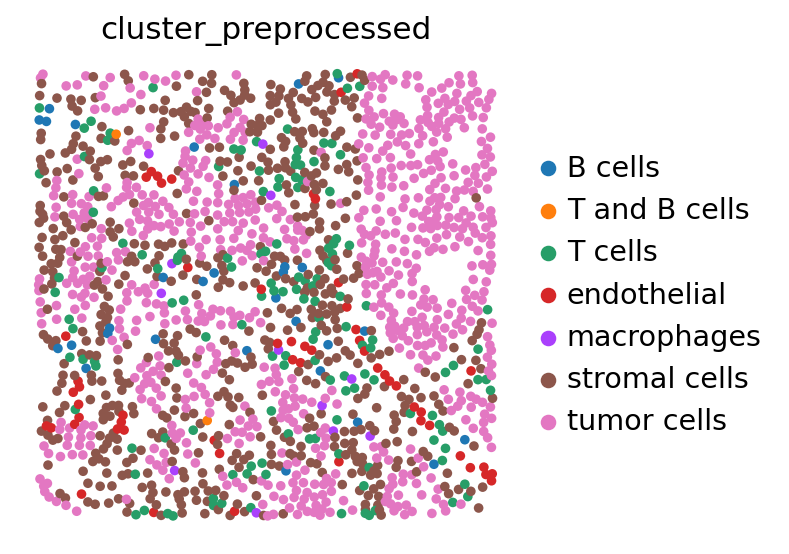

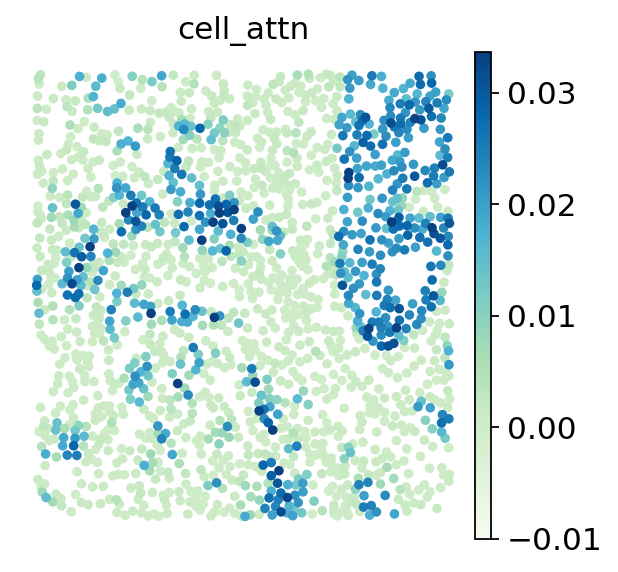

ZTMA208_slide_13_Cy9x3


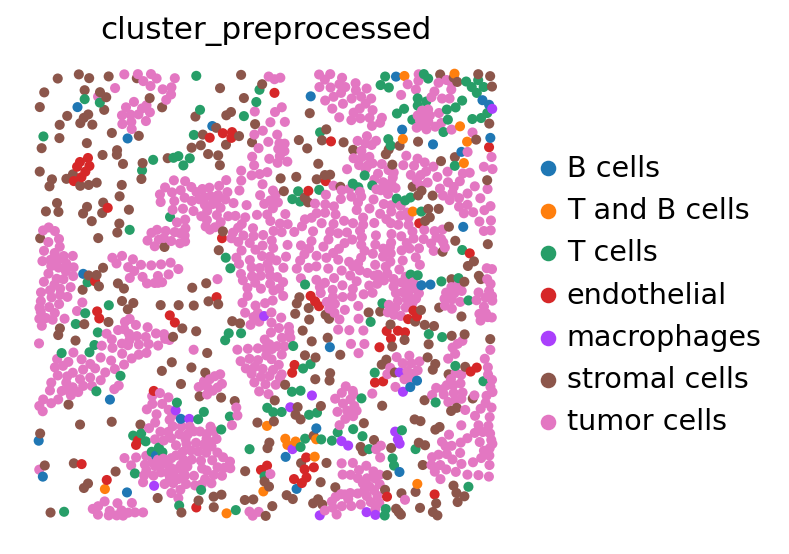

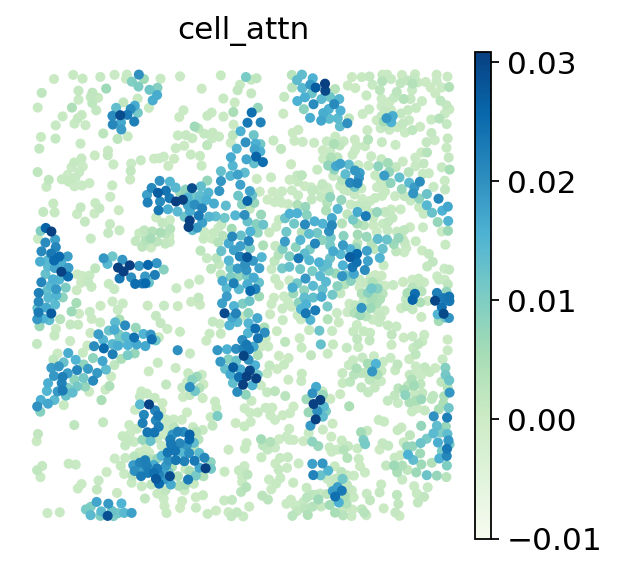

ZTMA208_slide_13_Cy9x5
slide ZTMA208_slide_13_Cy9x5 not in d.img_celldata
ZTMA208_slide_13_Cy9x2


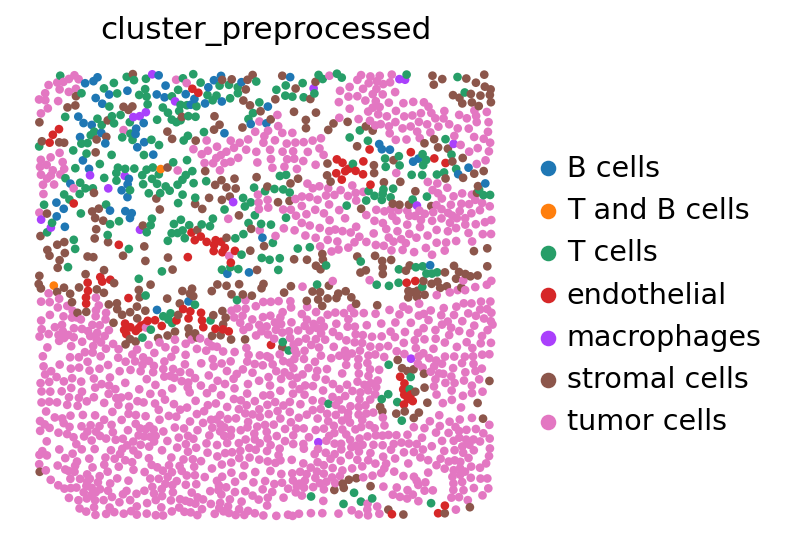

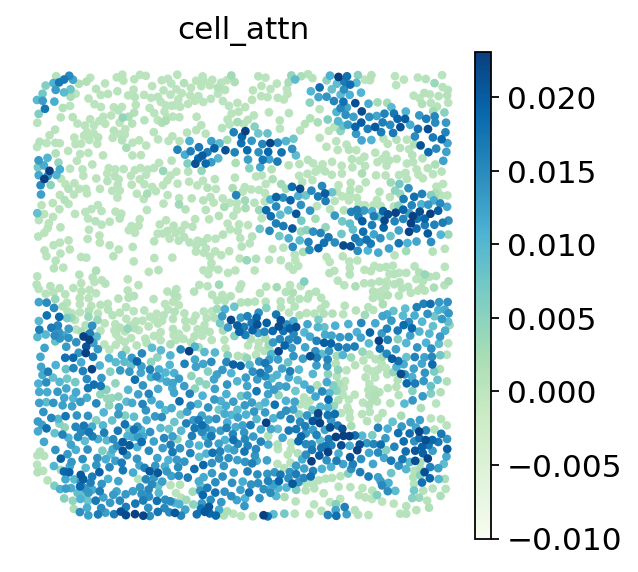

ZTMA208_slide_13_Cy9x4


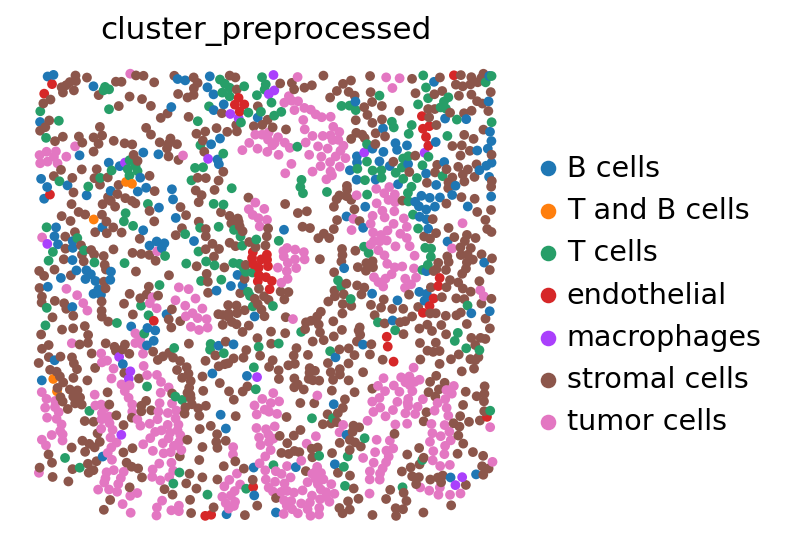

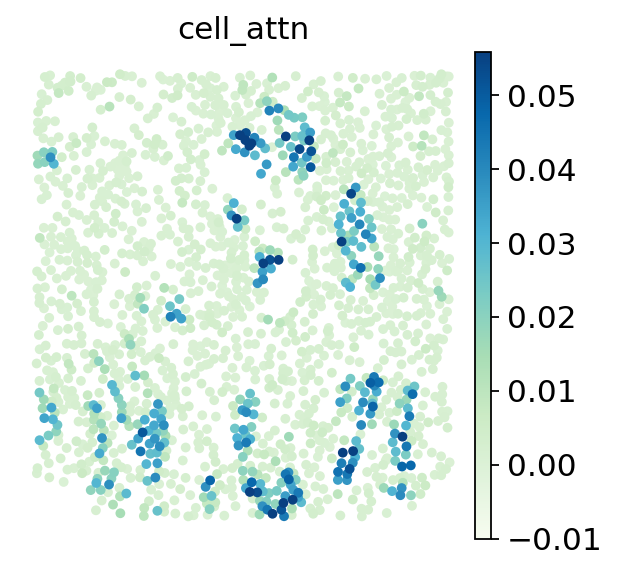

In [32]:
for slide in slides:
    print(slide)
    if slide not in d.img_celldata:
        print(f'slide {slide} not in d.img_celldata')
        continue
    adata_img = d.img_celldata[slide].copy()
    adata_img.obsm['spatial'] = adata_img.obsm['spatial'].astype(float)
    adata_img.obs['cell_attn'] = adata.obs['cell_attn'][adata_img.obs_names]
    adata_img.obsm['X_umap'] = adata_img.obsm['spatial'].copy()

    colors = []
    for ct in np.unique(adata_img.obs['cluster_preprocessed']):
        colors.append(color_map[ct])
    adata_img.uns['cluster_preprocessed_colors'] = colors

    sc.pl.umap(adata_img, color='cluster_preprocessed', frameon=False, save=f'{slide}_ct.svg')
    sc.pl.umap(adata_img, color='cell_attn', vmax='p99', vmin=-0.01, frameon=False, color_map='GnBu', save=f'{slide}_cell_attn.svg')

In [33]:
slide = 'ZTMA208_slide_13_Cy9x4'
adata_img = d.img_celldata[slide].copy()
adata_img.obsm['spatial'] = adata_img.obsm['spatial'].astype(float)
adata_img.obs['cell_attn'] = adata.obs['cell_attn'][adata_img.obs_names]
adata_img.obsm['X_umap'] = adata_img.obsm['spatial'].copy()
adata_img

AnnData object with n_obs × n_vars = 1548 × 34
    obs: 'core', 'PID', 'cluster', 'cluster_preprocessed', 'cell_attn'
    uns: 'metadata', 'img_keys', 'img_to_patient_dict', 'node_type_names', 'graph_covariates'
    obsm: 'spatial', 'node_types', 'X_umap'

In [36]:
adata_img.obs['tmp'] = np.nan

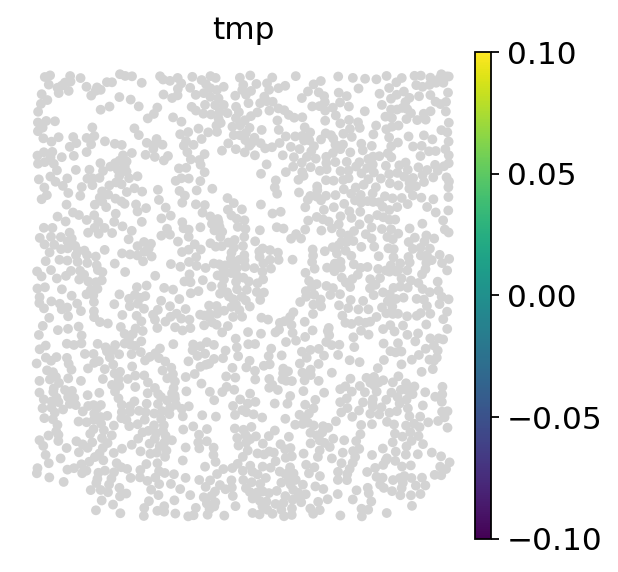

In [37]:
sc.pl.umap(adata_img, color='tmp', frameon=False, save=f'{slide}_example.svg')

In [34]:
slides = list(set(d.img_celldata.keys()).intersection(set(adata.obs['core'])))
len(slides)

274

In [35]:
# random slides
random.seed(0)
slides = random.sample(slides, 5)
slides

['ZTMA208_slide_19_Cy8x6',
 'ZTMA208_slide_37_Cy1x8',
 'ZTMA208_slide_21_Cy6x1',
 'ZTMA208_slide_25_By15x2',
 'ZTMA208_slide_62_By9x1']

ZTMA208_slide_19_Cy8x6


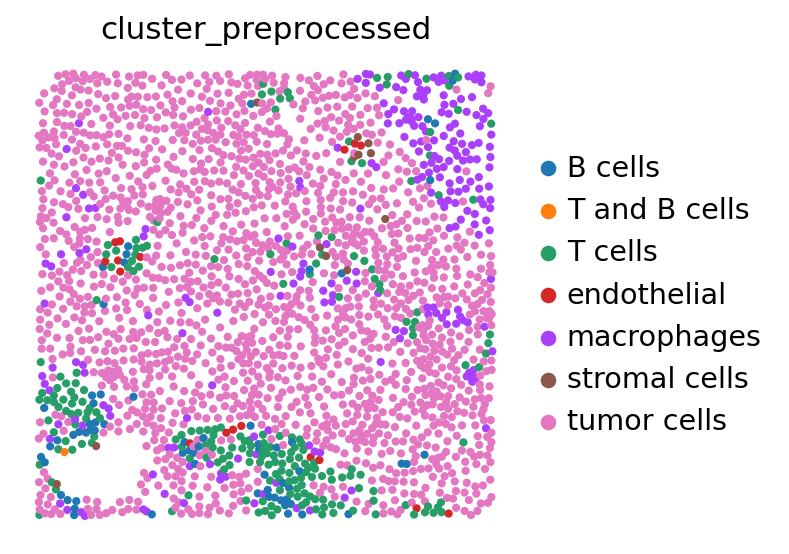

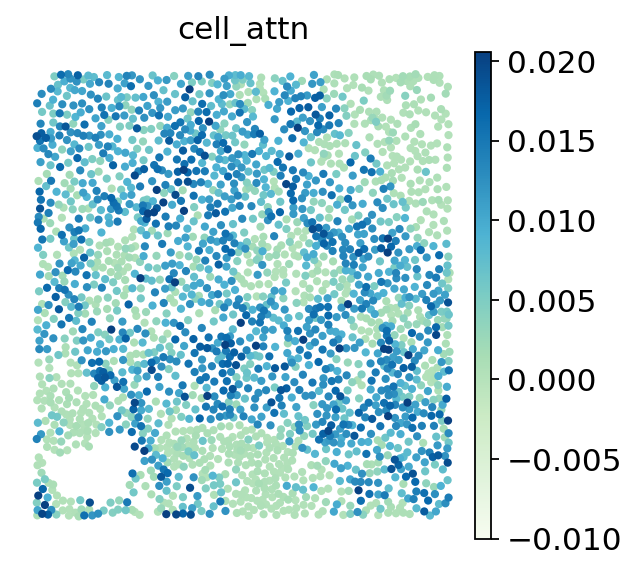

ZTMA208_slide_37_Cy1x8


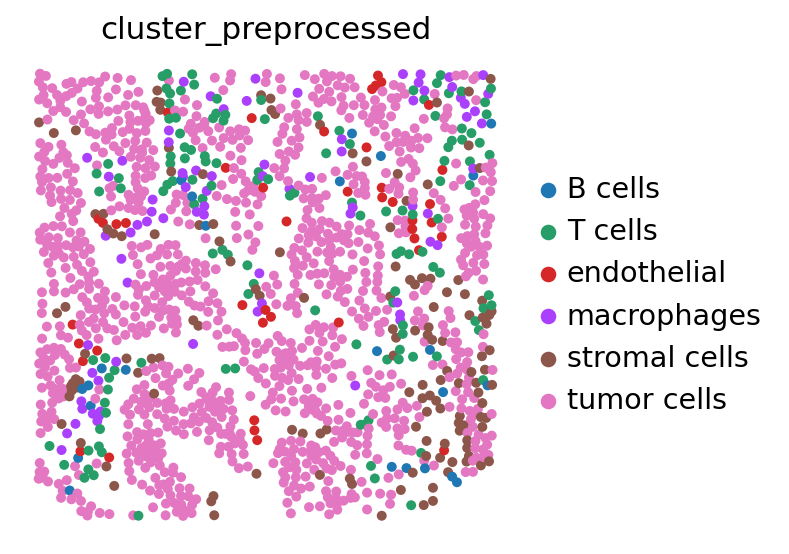

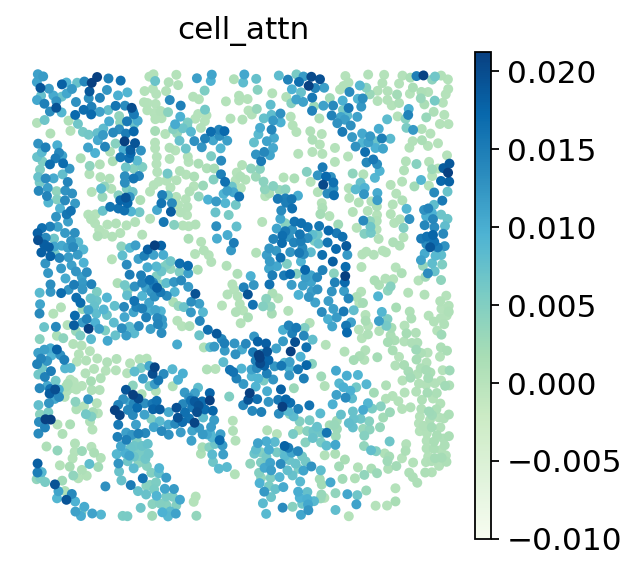

ZTMA208_slide_21_Cy6x1


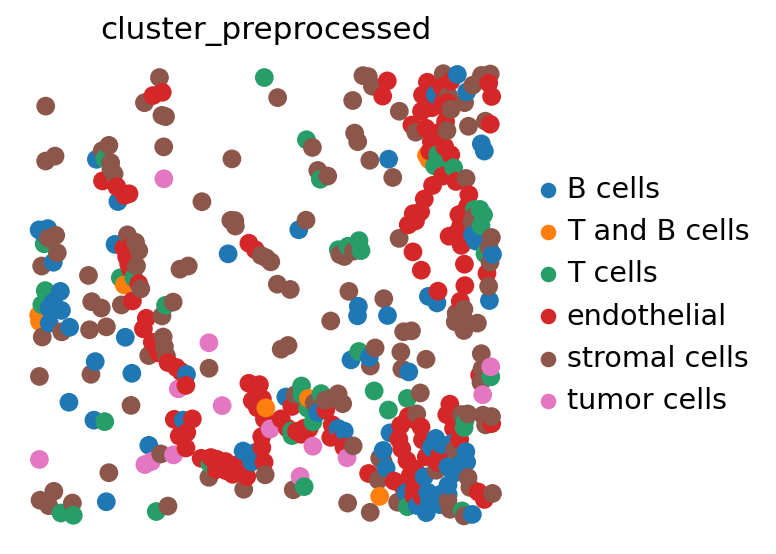

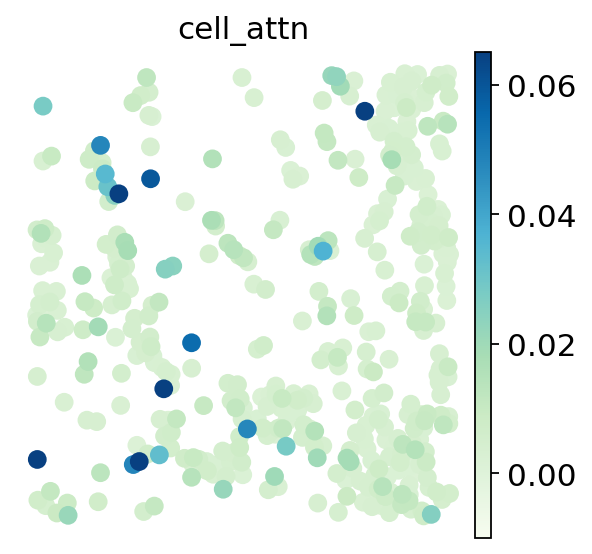

ZTMA208_slide_25_By15x2


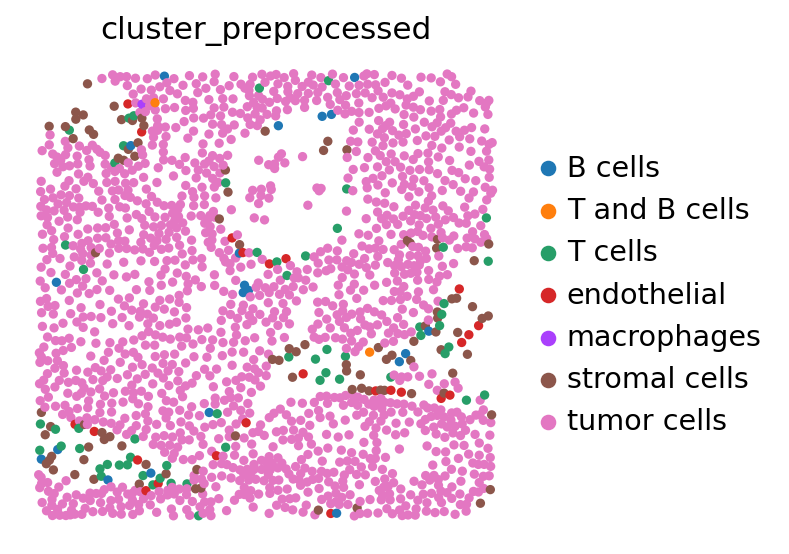

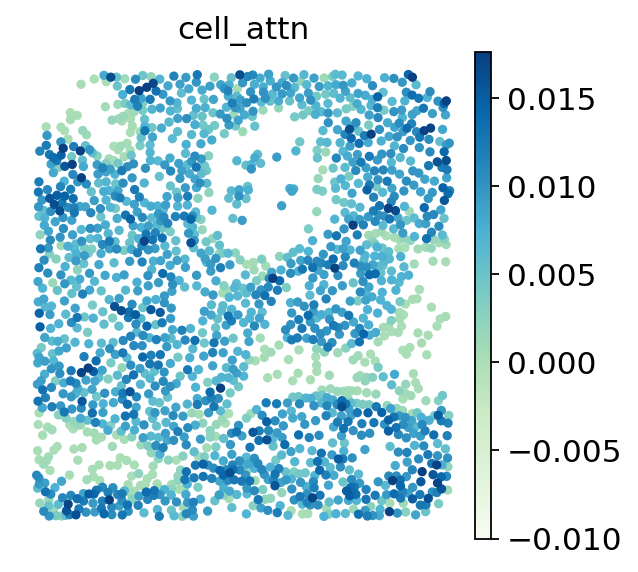

ZTMA208_slide_62_By9x1


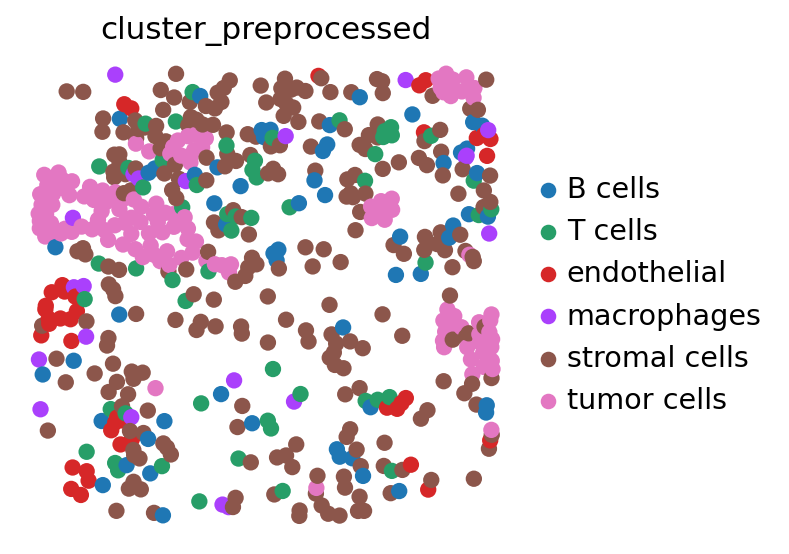

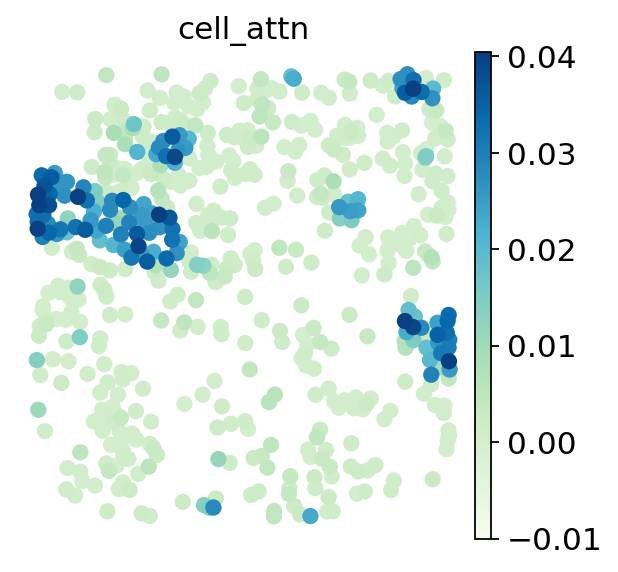

In [48]:
for slide in slides:
    print(slide)
    adata_img = d.img_celldata[slide].copy()
    adata_img.obsm['spatial'] = adata_img.obsm['spatial'].astype(float)
    adata_img.obs['cell_attn'] = adata.obs['cell_attn'][adata_img.obs_names]
    adata_img.obsm['X_umap'] = adata_img.obsm['spatial'].copy()

    colors = []
    for ct in np.unique(adata_img.obs['cluster_preprocessed']):
        colors.append(color_map[ct])
    adata_img.uns['cluster_preprocessed_colors'] = colors

    sc.pl.umap(adata_img, color='cluster_preprocessed', frameon=False, save=f'{slide}_ct.svg')
    sc.pl.umap(adata_img, color='cell_attn', vmax='p99', vmin=-0.01, frameon=False, color_map='GnBu', save=f'{slide}_cell_attn.svg')

In [19]:
len(adata.var_names)

38

In [20]:
adata.var_names

Index(['1021522Tm169Di EGFR', '1031747Er167Di ECadhe',
       '10331254Ir193Di Iridium', '112475Gd156Di Estroge',
       '117792Dy163Di GATA3', '1261726In113Di Histone', '1441101Er168Di Ki67',
       '174864Nd148Di SMA', '1921755Sm149Di Vimenti', '1971527Ho165Di bCaten',
       '198883Yb176Di cleaved', '201487Eu151Di cerbB', '207736Tb159Di p53',
       '234832Lu175Di panCyto', '2971330Dy161Di EpCAM',
       '3111576Nd143Di Cytoker', '312878Gd158Di Progest', '322787Nd150Di cMyc',
       '3281668Nd142Di Fibrone', '346876Sm147Di Keratin',
       '3521227Gd155Di Slug', '361077Dy164Di CD20', '378871Yb172Di vWF',
       '473968La139Di Histone', '483739Yb171Di Sox9', '651779Pr141Di Cytoker',
       '6967Gd160Di CD44', '71790Dy162Di CD45', '77877Nd146Di CD68',
       '8001752Sm152Di CD3epsi', '92964Er166Di Carboni',
       '971099Nd144Di Cytoker', '98922Yb174Di Cytoker', 'Nd145Di Twist',
       'phospho Erk12', 'phospho Histone', 'phospho S6', 'phospho mTOR'],
      dtype='object', name='chann